# Minimum Beacon Placement

Robot beacon localization project — Step 3. Reuses `map_gen.py` and `visibility.py`.

**Problem**: choose the **smallest** set of candidate beacons such that every sample point in free space sees $\ge 3$ selected beacons.

Formally — let $V_{ij}=1$ mean that sample point $i$ can see candidate beacon $j$, and let the decision variable $x_j\in\{0,1\}$ indicate whether beacon $j$ is placed:

$$\min \sum_j x_j \quad\text{s.t.}\quad \sum_j V_{ij}\,x_j \ge 3 \;\;\forall i,\qquad x_j\in\{0,1\}.$$

This is **set multi-cover**, which is NP-hard. We use two methods that cross-check each other:

1. **Greedy** — in each round pick the beacon that "removes the most under-coverage"; fast and scalable, with an $O(\log n)$ approximation guarantee, but not guaranteed to be optimal.
2. **ILP (CP-SAT)** — solve the integer program above directly; at the current scale it gives the **exact optimum**, the baseline for measuring greedy's quality.

Finally, across many random maps we look at how the number of beacons changes with map size and complexity.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from map_gen import make_map
from visibility import sample_points, wall_arrays, visibility_matrix

K = 3   # minimum number of beacons each point must see

# load the data exported by the previous step (the main map, seed=42)
data = np.load('visibility_data.npz')
V = data['V']
P = data['P']
beacons = [tuple(b) for b in data['beacons']]
cells = {tuple(c) for c in data['cells']}
W1, W2 = data['W1'], data['W2']
GRID_W, GRID_H, TARGET_CELLS, HOLE_CELLS, SEED, RES = data['meta']
_, segments, _, _ = make_map(GRID_W, GRID_H, TARGET_CELLS, HOLE_CELLS, SEED)

print(f'V = {V.shape}  ({V.shape[0]} points x {V.shape[1]} candidate beacons)')
print(f'visible beacons per point: min={V.sum(1).min()}  => the k={K} cover problem is feasible' )

V = (1760, 144)  (1760 points x 144 candidate beacons)
visible beacons per point: min=5  => the k=3 cover problem is feasible


## 0. Feasibility and the requirement vector

If a sample point can see only $r<3$ beacons even with **all** candidates placed, then "seeing 3" is impossible for it.
To keep the problem always feasible, each point's requirement is set to $r_i=\min(3,\ \text{total number of candidate beacons it can see})$.
On the current main map every point sees at least 5, so $r_i\equiv 3$. This mainly serves as a safety net for narrow dead corners
that may appear in the multi-map statistics.

In [2]:
def requirements(V, k=K):
    """Coverage requirement of each point: r_i = min(k, total visible candidates)"""
    return np.minimum(k, V.sum(axis=1)).astype(int)


req = requirements(V)
print(f'requirement distribution: points needing 3: {int((req == 3).sum())} / {len(req)},'
      f' points with a forced lower requirement (<3): {int((req < 3).sum())}')

requirement distribution: points needing 3: 1760 / 1760, points with a forced lower requirement (<3): 0


## 1. Greedy algorithm

Track how many beacons each point is "still missing" ($\text{deficit}_i$, initially $r_i$). In each round, the **gain** of a candidate beacon
= the number of points it can see that are still under-covered ($\text{deficit}>0$). Add the candidate with the largest gain,
decrease the deficit of those points by 1, and repeat until every deficit reaches zero.

This is the standard greedy algorithm for set multi-cover, with approximation ratio $H(n)=O(\log n)$.

In [3]:
def greedy_cover(V, k=K):
    """Greedy k-fold cover; returns the list of selected beacon indices"""
    N, M = V.shape
    deficit = requirements(V, k).copy()
    chosen, used = [], np.zeros(M, dtype=bool)
    Vb = V.astype(bool)
    while deficit.max() > 0:
        need = deficit > 0                       # points still under-covered
        gain = (Vb & need[:, None]).sum(axis=0)  # gain of each candidate
        gain[used] = -1                          # never pick the same one twice
        j = int(gain.argmax())
        if gain[j] <= 0:
            break                                # no further improvement possible (should not happen)
        used[j] = True
        chosen.append(j)
        deficit[Vb[:, j]] = np.maximum(0, deficit[Vb[:, j]] - 1)
    return chosen


def verify(V, chosen, k=K):
    """Check a solution: returns (satisfied or not, actual coverage count per point)"""
    counts = V[:, chosen].sum(axis=1) if chosen else np.zeros(V.shape[0], int)
    return bool((counts >= requirements(V, k)).all()), counts


t0 = time.time()
g_sel = greedy_cover(V)
g_ok, g_counts = verify(V, g_sel)
print(f'Greedy: {len(g_sel)} beacons, {time.time() - t0:.3f}s, constraints satisfied={g_ok}')
print(f'actual coverage per point: min={g_counts.min()} median={int(np.median(g_counts))} max={g_counts.max()}')

Greedy: 30 beacons, 0.008s, constraints satisfied=True
actual coverage per point: min=3 median=8 max=13


### Dependency check

The ILP part needs Google OR-Tools. The next cell checks whether it is installed in the current kernel and installs it automatically if not.

In [4]:
import subprocess
import sys

try:
    from ortools.sat.python import cp_model
    print('ortools already available')
except ModuleNotFoundError:
    print('ortools not found — installing into', sys.executable)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ortools'])
    from ortools.sat.python import cp_model
    print('ortools installed')

ortools already available


## 2. Exact ILP solution (CP-SAT)

Solve the integer program directly with Google OR-Tools' CP-SAT solver to get a **provably optimal** number of beacons.
The greedy solution is passed as a warm-start hint to help the solver converge faster.

In [5]:
def ilp_cover(V, k=K, hint=None, time_limit=30.0):
    """Minimum k-fold cover with CP-SAT. Returns (selected indices, status string)"""
    N, M = V.shape
    req = requirements(V, k)
    model = cp_model.CpModel()
    x = [model.NewBoolVar(f'x{j}') for j in range(M)]
    for i in range(N):
        cover = [x[j] for j in range(M) if V[i, j]]
        model.Add(sum(cover) >= int(req[i]))
    model.Minimize(sum(x))
    if hint:
        for j in range(M):
            model.AddHint(x[j], 1 if j in set(hint) else 0)
    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = time_limit
    solver.parameters.num_search_workers = 8
    status = solver.Solve(model)
    sel = [j for j in range(M) if solver.Value(x[j])]
    name = {cp_model.OPTIMAL: 'OPTIMAL', cp_model.FEASIBLE: 'FEASIBLE',
            cp_model.INFEASIBLE: 'INFEASIBLE'}.get(status, str(status))
    return sel, name


t0 = time.time()
i_sel, i_status = ilp_cover(V, hint=g_sel)
i_ok, i_counts = verify(V, i_sel)
print(f'ILP: {len(i_sel)} beacons, {time.time() - t0:.2f}s, status={i_status}, constraints satisfied={i_ok}')
print(f'\nComparison:  greedy {len(g_sel)}  vs  ILP optimal {len(i_sel)}  '
      f'(greedy uses {len(g_sel) - len(i_sel)} more than optimal)')

ILP: 24 beacons, 0.64s, status=OPTIMAL, constraints satisfied=True

Comparison:  greedy 30  vs  ILP optimal 24  (greedy uses 6 more than optimal)


## 3. Visual comparison of the two solutions

Red stars = selected beacons; background color = number of beacons each sample point sees (brighter = more). Both solutions should satisfy $\ge 3$ everywhere.

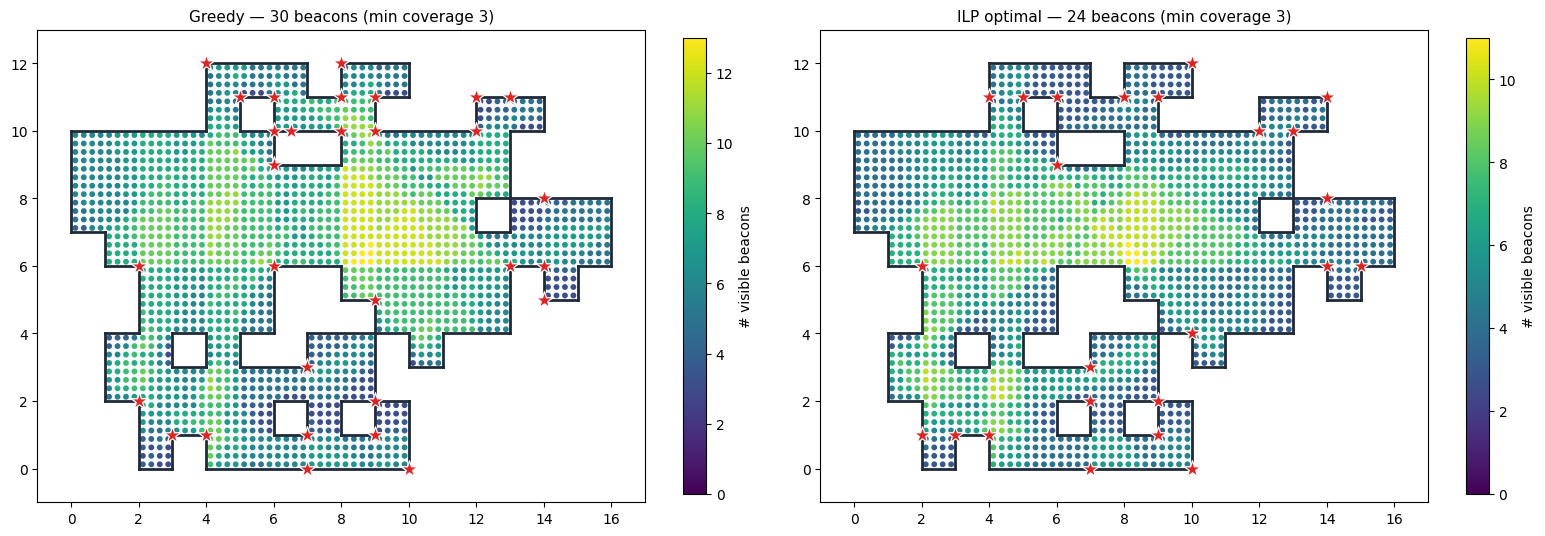

In [6]:
def plot_solution(P, counts, chosen, cells, segments, beacons, ax, title=''):
    for (x, y) in cells:
        ax.add_patch(Rectangle((x, y), 1, 1, facecolor='#f8fafc', edgecolor='none'))
    sc = ax.scatter(P[:, 0], P[:, 1], c=counts, s=10, cmap='viridis',
                    vmin=0, vmax=max(6, counts.max()), zorder=2)
    plt.colorbar(sc, ax=ax, shrink=0.8, label='# visible beacons')
    for (x1, y1), (x2, y2) in segments:
        ax.plot([x1, x2], [y1, y2], color='#1f2937', linewidth=2, zorder=3)
    cb = np.array([beacons[j] for j in chosen], dtype=float)
    ax.scatter(cb[:, 0], cb[:, 1], s=160, marker='*', color='#dc2626',
               edgecolor='white', linewidth=0.9, zorder=4)
    xs = [x for x, _ in cells]; ys = [y for _, y in cells]
    ax.set_xlim(min(xs) - 1, max(xs) + 2)
    ax.set_ylim(min(ys) - 1, max(ys) + 2)
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=11)


fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_solution(P, g_counts, g_sel, cells, segments, beacons, axes[0],
              title=f'Greedy — {len(g_sel)} beacons (min coverage {g_counts.min()})')
plot_solution(P, i_counts, i_sel, cells, segments, beacons, axes[1],
              title=f'ILP optimal — {len(i_sel)} beacons (min coverage {i_counts.min()})')
plt.tight_layout()
plt.show()

## 4. Statistics over many random maps

For several random seeds, run the full pipeline map generation → visibility matrix → greedy + ILP, and record the minimum number of beacons.
See how it changes with map size, and how far greedy is from the optimum.

> Each map is solved under a time limit; if the ILP cannot prove optimality within the limit, the best feasible upper bound found so far is recorded.

In [7]:
def count_reflex_corners(cells):
    """Count reflex corners, as one measure of map complexity.
    A lattice point is a reflex corner of the free space if exactly 3 of the 4 cells in the 2x2 block around it are free."""
    pts = set()
    for (x, y) in cells:
        pts.update([(x, y), (x + 1, y), (x, y + 1), (x + 1, y + 1)])
    reflex = 0
    for (px, py) in pts:
        quad = [(px - 1, py - 1), (px, py - 1), (px - 1, py), (px, py)]
        if sum(c in cells for c in quad) == 3:
            reflex += 1
    return reflex


def solve_map(seed, w=16, h=12, target=120, holes=10, res=4, time_limit=20.0):
    cells, segments, corners, mids = make_map(w, h, target, holes, seed)
    beacons = corners + mids
    W1, W2 = wall_arrays(segments)
    P = sample_points(cells, res)
    V = visibility_matrix(beacons, P, cells, W1, W2)
    g = greedy_cover(V)
    isel, status = ilp_cover(V, hint=g, time_limit=time_limit)
    return {
        'seed': seed, 'area': len(cells), 'reflex': count_reflex_corners(cells),
        'candidates': len(beacons), 'points': len(P),
        'greedy': len(g), 'ilp': len(isel), 'status': status,
    }


# vary the map area too, so that a trend in the area vs. beacon-count relation can show up
rows = []
configs = [(60, 4), (80, 6), (100, 8), (120, 10), (150, 12)]  # (target_cells, holes)
for seed in range(2):
    for target, holes in configs:
        r = solve_map(seed * 100 + target, target=target, holes=holes)
        rows.append(r)
        print(f"area {r['area']:3d} | reflex {r['reflex']:2d} | "
              f"cand {r['candidates']:3d} | points {r['points']:4d} | greedy {r['greedy']:2d} | "
              f"ilp {r['ilp']:2d} ({r['status']})")

area  56 | reflex 28 | cand  96 | points  896 | greedy 17 | ilp 16 (OPTIMAL)
area  74 | reflex 31 | cand 116 | points 1184 | greedy 25 | ilp 20 (OPTIMAL)
area  92 | reflex 37 | cand 124 | points 1472 | greedy 25 | ilp 20 (OPTIMAL)
area 110 | reflex 47 | cand 160 | points 1760 | greedy 33 | ilp 27 (OPTIMAL)
area 138 | reflex 44 | cand 144 | points 2208 | greedy 29 | ilp 23 (OPTIMAL)
area  56 | reflex 23 | cand  96 | points  896 | greedy 20 | ilp 16 (OPTIMAL)
area  74 | reflex 37 | cand 120 | points 1184 | greedy 25 | ilp 21 (OPTIMAL)
area  92 | reflex 41 | cand 132 | points 1472 | greedy 29 | ilp 25 (OPTIMAL)
area 110 | reflex 58 | cand 188 | points 1760 | greedy 34 | ilp 28 (OPTIMAL)
area 138 | reflex 52 | cand 156 | points 2208 | greedy 25 | ilp 21 (OPTIMAL)


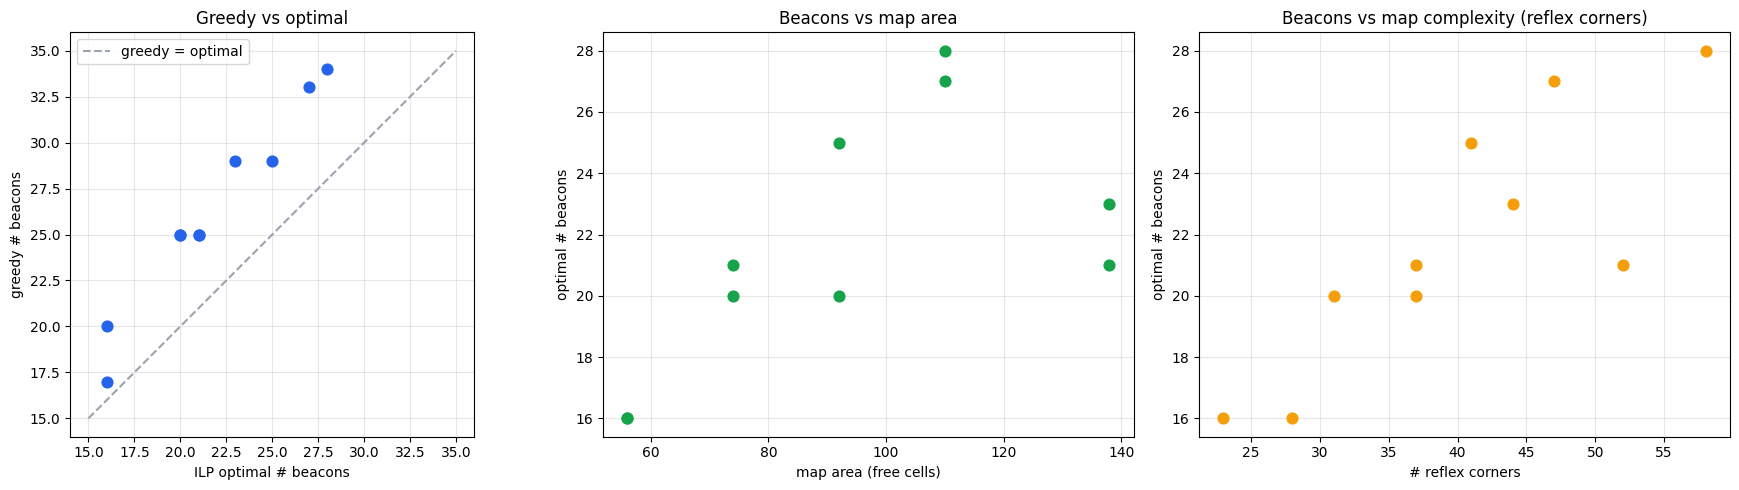

gap between greedy and optimal: mean 4.50, max 6, greedy is optimal on 0/10 maps


In [8]:
area = np.array([r['area'] for r in rows])
reflex = np.array([r['reflex'] for r in rows])
g_n = np.array([r['greedy'] for r in rows])
i_n = np.array([r['ilp'] for r in rows])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) greedy vs optimal
axes[0].scatter(i_n, g_n, s=60, color='#2563eb', zorder=3)
lim = [min(i_n.min(), g_n.min()) - 1, max(i_n.max(), g_n.max()) + 1]
axes[0].plot(lim, lim, '--', color='#9ca3af', label='greedy = optimal')
axes[0].set_xlabel('ILP optimal # beacons'); axes[0].set_ylabel('greedy # beacons')
axes[0].set_title('Greedy vs optimal'); axes[0].legend(); axes[0].set_aspect('equal')

# (b) beacon count vs area
axes[1].scatter(area, i_n, s=60, color='#16a34a', zorder=3)
axes[1].set_xlabel('map area (free cells)'); axes[1].set_ylabel('optimal # beacons')
axes[1].set_title('Beacons vs map area')

# (c) beacon count vs number of reflex corners
axes[2].scatter(reflex, i_n, s=60, color='#f59e0b', zorder=3)
axes[2].set_xlabel('# reflex corners'); axes[2].set_ylabel('optimal # beacons')
axes[2].set_title('Beacons vs map complexity (reflex corners)')

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

gap = g_n - i_n
print(f'gap between greedy and optimal: mean {gap.mean():.2f}, max {gap.max()}, '
      f'greedy is optimal on {int((gap == 0).sum())}/{len(gap)} maps')

## Summary

The project's core loop now works end to end: **random map → wall geometry and beacon candidates → visibility matrix → minimum-beacon solving (greedy + exact ILP) → visualization and statistics**. The three notebooks run independently, with the geometry/visibility logic packaged in `map_gen.py` and `visibility.py`.

**Observations for the report**: greedy is clearly worse than the optimum here — it never matched the ILP on the 10 maps, using 4.5 more beacons on average (up to 6; about 20% more), so solving exactly is worth it at this scale. The optimum also rises with map area in this experiment, but area is confounded with complexity: `configs` increases the number of holes together with the area. On 472 verified maps with independently drawn area and holes (`analysis.ipynb`, Question 4), the count is essentially unrelated to area and is driven by the number of reflex corners — reflex corners are exactly what blocks lines of sight and makes coverage hard. Note also that all counts in this notebook are on the `RES=4` sample points only; `refinement.ipynb` shows that this underestimates the true minimum.

**Possible extensions**:

- *Continuous guarantee*: the current results are a sample-point approximation. A visibility decomposition (cutting the free space into cells along critical lines of sight) would give a rigorous proof that holds over the continuous region.
- *Denser beacon candidates*: adding sample points along the walls, or candidates along the angle bisectors of reflex corners, may reduce the number of beacons further.
- *Localization quality*: currently we only require "sees 3". Adding a geometric accuracy constraint (avoiding near-collinear beacons that make triangulation ill-conditioned) would upgrade "can see" to "can localize reliably".
- *Scale and performance*: the ILP slows down on larger maps; an LP-relaxation lower bound + greedy upper bound can bracket the optimum, or column generation can be used.